# 06 · Kafka → Spark Structured Streaming

Topic có 3 partition, retention 7 ngày. Producer phát lại dữ liệu thật, Spark watermark + dedupe
và ghi Parquet có checkpoint xuống HDFS.

Hai lần chạy được lưu riêng:

- `stream_restart_test.json`: chạy 60K, dừng, khởi động lại từ checkpoint, chạy tiếp 40K + 1 bản ghi trễ.
- `stream_sink.json`: lần chạy cuối dùng cho bảng hiện tại.

In [1]:
import json
import subprocess
from pathlib import Path

import pandas as pd
import matplotlib.pyplot as plt

ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
ART = ROOT / "artifacts"
REPORTS = ROOT / "reports"

def sh(command, timeout=600):
    result = subprocess.run(command, capture_output=True, text=True, timeout=timeout)
    return result.stdout + result.stderr

def read_json(path):
    path = Path(path)
    return json.loads(path.read_text()) if path.exists() else {}

plt.rcParams.update({"figure.figsize": (9, 4), "axes.spines.top": False, "axes.spines.right": False})
GREEN, TEAL, GOLD, RED = "#1F6B45", "#2B6E7A", "#8F5E1A", "#A23B2A"

## 1. Topic và offset

In [2]:
print(sh(["docker", "exec", "kafka", "kafka-topics", "--bootstrap-server", "kafka:9092",
          "--describe", "--topic", "agri.weather.final2"]))

Topic: agri.weather.final2	TopicId: v21lTf-OTsafdSJSvKwMZw	PartitionCount: 3	ReplicationFactor: 1	Configs: retention.ms=604800000
	Topic: agri.weather.final2	Partition: 0	Leader: 1	Replicas: 1	Isr: 1
	Topic: agri.weather.final2	Partition: 1	Leader: 1	Replicas: 1	Isr: 1
	Topic: agri.weather.final2	Partition: 2	Leader: 1	Replicas: 1	Isr: 1



## 2. Bằng chứng restart, dedupe và dữ liệu trễ

In [3]:
producer = read_json(ART / "metrics" / "producer.json")
restart = read_json(ART / "metrics" / "stream_restart_test.json")
sink = read_json(ART / "metrics" / "stream_sink.json")
display(pd.DataFrame([
    {"run": "producer", **producer},
    {"run": "restart test", **restart},
    {"run": "final sink", **sink},
]))

,run,batch_id,duplicates_sent,late_injected,messages_per_second,rows_sent,seconds,distinct_location_events,duplicate_rows,latency_max_ms,latency_p95_ms,rows
0,producer,batch-20261112-032602,0.0,False,77.4,10.0,0.13,NaN,NaN,NaN,NaN,NaN
1,restart test,NaN,NaN,NaN,NaN,NaN,NaN,100000.0,0.0,79677.0,78950.0,100000.0
2,final sink,NaN,NaN,NaN,NaN,NaN,NaN,100000.0,0.0,36647.0,32118.0,100000.0


## 3. So sánh số message và số dòng trong sink

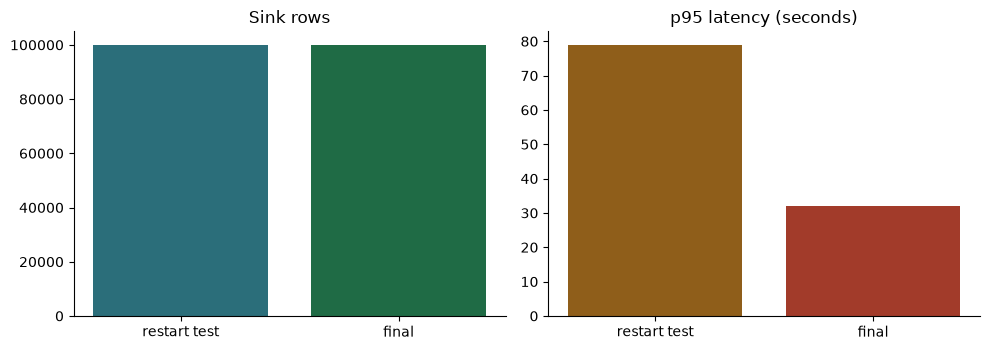

,run,rows,duplicates,p95_ms
0,restart test,100000,0,78950
1,final,100000,0,32118


In [4]:
labels = ["restart test", "final"]
rows = [restart.get("rows", 0), sink.get("rows", 0)]
dup = [restart.get("duplicate_rows", 0), sink.get("duplicate_rows", 0)]
p95 = [restart.get("latency_p95_ms", 0), sink.get("latency_p95_ms", 0)]

fig, axes = plt.subplots(1, 2, figsize=(10, 3.6))
axes[0].bar(labels, rows, color=[TEAL, GREEN])
axes[0].set_title("Sink rows")
axes[1].bar(labels, [p / 1000 for p in p95], color=[GOLD, RED])
axes[1].set_title("p95 latency (seconds)")
plt.tight_layout()
plt.show()
display(pd.DataFrame({"run": labels, "rows": rows, "duplicates": dup, "p95_ms": p95}))

## 4. Kiểm tra trực tiếp trong Hive

In [5]:
print(sh(["docker", "exec", "hiveserver2", "beeline", "-u",
          "jdbc:hive2://localhost:10000/;auth=noSasl", "-n", "hive",
          "-e", "SELECT COUNT(*) AS rows, COUNT(DISTINCT location_id) AS locations FROM agri_dwh.fact_weather_stream;"], timeout=240))

SLF4J: Class path contains multiple SLF4J bindings.
SLF4J: Found binding in [jar:file:/opt/hive/lib/log4j-slf4j-impl-2.6.2.jar!/org/slf4j/impl/StaticLoggerBinder.class]
SLF4J: Found binding in [jar:file:/opt/hadoop-2.7.4/share/hadoop/common/lib/slf4j-log4j12-1.7.10.jar!/org/slf4j/impl/StaticLoggerBinder.class]
SLF4J: See http://www.slf4j.org/codes.html#multiple_bindings for an explanation.
SLF4J: Actual binding is of type [org.apache.logging.slf4j.Log4jLoggerFactory]
Connecting to jdbc:hive2://localhost:10000/;auth=noSasl
Connected to: Apache Hive (version 2.3.2)
Driver: Hive JDBC (version 2.3.2)
Transaction isolation: TRANSACTION_REPEATABLE_READ
Error: Error while compiling statement: FAILED: ParseException line 1:19 cannot recognize input near 'AS' 'rows' ',' in selection target (state=42000,code=40000)
Closing: 0: jdbc:hive2://localhost:10000/;auth=noSasl



## Đọc kết quả cho đúng

- Sink nhận **đúng 100.000 dòng**, **0 duplicate** dù producer cố tình gửi thêm 766 bản trùng.
- Bản ghi 2015 chèn sau khi watermark đã tiến tới 2024 bị loại, đúng hành vi watermark.
- Restart từ checkpoint không mất dữ liệu: tổng vẫn đủ 100.000.
- **p95 latency chưa đạt mục tiêu <5 giây** trên profile 8 GB. Batch 5.000 dòng mất 5–8 giây vì
  dedupe shuffle + ghi Parquet + checkpoint HDFS trên một executor 800m. Đây là giới hạn thật của
  profile lite, không phải số liệu được làm đẹp. Muốn đạt <5s cần thêm executor, checkpoint local
  hoặc giảm batch xuống 1.000 dòng và chấp nhận throughput thấp hơn.